In [15]:
import pandas as  pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [16]:
df=pd.read_csv('../datasets/crop_production.csv');

In [17]:
df.head(30)

,index,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.00
1,1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.00
2,2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.00
3,3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.00
4,4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.00
5,5,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Coconut,18168.0,65100000.00
6,6,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Dry ginger,36.0,100.00
7,7,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Sugarcane,1.0,2.00
8,8,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Sweet potato,5.0,15.00
9,9,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Tapioca,40.0,169.00


In [18]:
df.shape

(246091, 8)

In [19]:
df.isnull().sum()

index               0
State_Name          0
District_Name       0
Crop_Year           0
Season              0
Crop                0
Area                0
Production       3730
dtype: int64

In [20]:
df = df.dropna(subset=['Production'])

In [21]:
df.isnull().sum()

index            0
State_Name       0
District_Name    0
Crop_Year        0
Season           0
Crop             0
Area             0
Production       0
dtype: int64

In [22]:
df = df.drop(columns=['index'])  # Drop index column

In [23]:
df.isnull().sum()

State_Name       0
District_Name    0
Crop_Year        0
Season           0
Crop             0
Area             0
Production       0
dtype: int64

In [24]:
df['Yield'] = df['Production'] / df['Area']

In [25]:
df.head()

,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production,Yield
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.0,1.594896
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.0,0.500000
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.0,3.147059
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.0,3.642045
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.0,0.229167


In [26]:
df.isnull().sum()

State_Name       0
District_Name    0
Crop_Year        0
Season           0
Crop             0
Area             0
Production       0
Yield            0
dtype: int64

In [27]:
import pandas as pd
import pickle
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

df = pd.read_csv('../datasets/crop_data_with_yield.csv') 


df = df.dropna(subset=['Yield'])
df = df[~df['Yield'].isin([float('inf'), float('-inf')])]


df = df[df['Yield'] < 1e6]  

categorical_columns = ['State_Name', 'Crop', 'Season', 'Crop_Year']

X = df[categorical_columns]
y = df['Yield']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns)
    ]
)

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42))
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

with open('xgb_crop_yield_pipeline.pkl', 'wb') as f:
    pickle.dump(model, f)

print(" Model retrained and saved WITHOUT Area and Production.")


R2 Score: 0.8336217219797465
Mean Squared Error: 90006.68586981104
 Model retrained and saved WITHOUT Area and Production.


In [28]:
import pickle
import pandas as pd

def predict_yield(state, crop, season, crop_year):
    # Load the saved pipeline
    with open('xgb_crop_yield_pipeline.pkl', 'rb') as f:
        model = pickle.load(f)

    input_data = pd.DataFrame([{
        'State_Name': state,
        'Crop': crop,
        'Season': season,
        'Crop_Year': crop_year
    }])

    predicted_yield = model.predict(input_data)[0]

    print(f"🌾 Predicted Crop Yield: {predicted_yield:.2f} tons/hectare")
    return predicted_yield


In [29]:
predict_yield("Bihar", "Wheat", "Rabi", 1998)


🌾 Predicted Crop Yield: 1.21 tons/hectare


np.float32(1.2051084)

In [31]:
import pandas as pd
import json

df = pd.read_csv('../datasets/crop_data_with_yield.csv') 

categorical_columns = ['State_Name', 'Crop', 'Season', 'Crop_Year']

unique_values = {col: sorted(df[col].dropna().unique().tolist()) for col in categorical_columns}

for col, values in unique_values.items():
    print(f"\n🔹 {col} ({len(values)}):\n{values}")

with open('unique_categorical_values.json', 'w') as f:
    json.dump(unique_values, f, indent=4)

print("\n Unique categorical values extracted and saved to 'unique_categorical_values.json'")



🔹 State_Name (33):
['Andaman and Nicobar Islands', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Dadra and Nagar Haveli', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir ', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana ', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

🔹 Crop (124):
['Apple', 'Arcanut (Processed)', 'Arecanut', 'Arhar/Tur', 'Ash Gourd', 'Atcanut (Raw)', 'Bajra', 'Banana', 'Barley', 'Bean', 'Beans & Mutter(Vegetable)', 'Beet Root', 'Ber', 'Bhindi', 'Bitter Gourd', 'Black pepper', 'Blackgram', 'Bottle Gourd', 'Brinjal', 'Cabbage', 'Cardamom', 'Carrot', 'Cashewnut', 'Cashewnut Processed', 'Cashewnut Raw', 'Castor seed', 'Cauliflower', 'Citrus Fruit', 'Coconut ', 'Coffee', 'Colocosia', 'Cond-spcs other', 'Coriander', 'Cotton(lint)', 'Cowpea(Lobia)', 'C

In [ ]:
import pandas as pd
import pickle
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

df = pd.read_csv('crop_data_with_yield.csv')  

df = df.dropna(subset=['Yield'])
df = df[~df['Yield'].isin([float('inf'), float('-inf')])]
df = df[df['Yield'] < 1e6]  

categorical_columns = ['State_Name', 'Crop', 'Season', 'Crop_Year']

X = df[categorical_columns]
y = df['Yield']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns)
    ]
)

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42))
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

with open('xgb_crop_yield_pipeline.pkl', 'wb') as f:
    pickle.dump(model, f)

print(" Model retrained and saved WITHOUT Area and Production.")


R2 Score: 0.8336217219797464
Mean Squared Error: 90006.68586981106
✅ Model retrained and saved WITHOUT Area and Production.


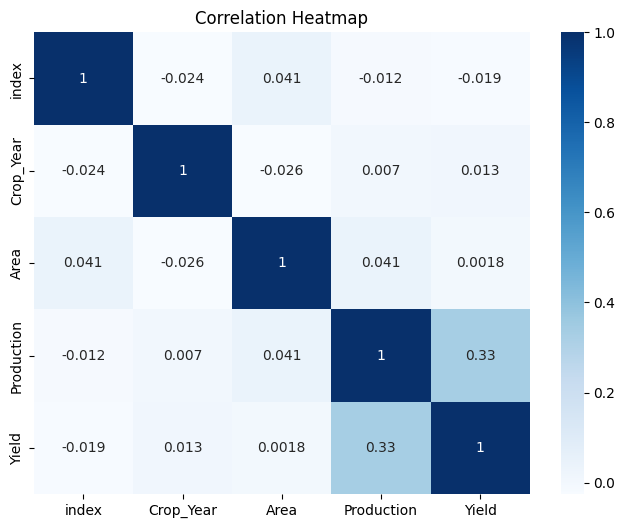

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.select_dtypes(include=['number']).corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="Blues")
plt.title("Correlation Heatmap")
plt.savefig("correlation_heatmap.png")
plt.show()

In [ ]:
import sys
print(f"Python path: {sys.executable}")
print(f"Python version: {sys.version}")

Python path: C:\Users\dines\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe
Python version: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


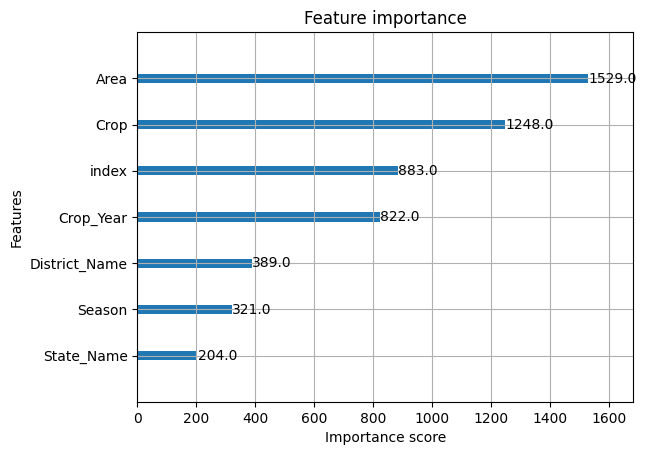

In [36]:
from xgboost import plot_importance
import matplotlib.pyplot as plt

plot_importance(model)

plt.savefig("feature_importance.png")

plt.show()

In [34]:
print(type(model))
print(model)

<class 'sklearn.pipeline.Pipeline'>
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['State_Name', 'Crop',
                                                   'Season', 'Crop_Year'])])),
                ('regressor',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              colsample_bylevel=None, colsample_bynode=None,
                              colsample_bytree=None, device=None,
                              early_stopping_rounds=None,
                              enable_categorica...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.1,
          

Training model...
R² Score: 0.9362
RMSE: 5067909.9578


<Figure size 1000x800 with 0 Axes>

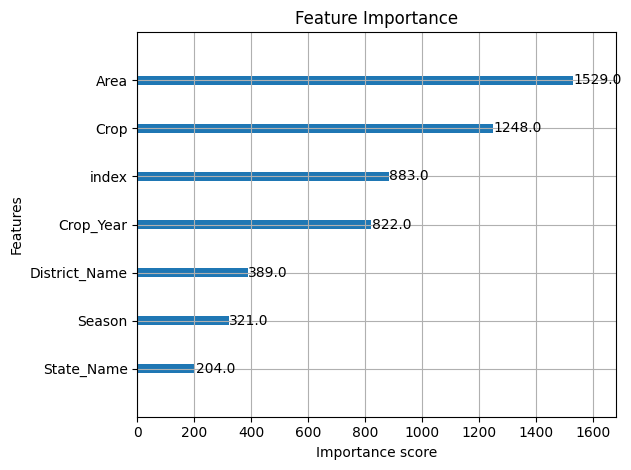

In [35]:
import pandas as pd
import numpy as np
import pickle
from xgboost import XGBRegressor, plot_importance
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

# Load dataset
file_path = '../datasets/crop_production.csv'
df = pd.read_csv(file_path)

# Preprocess (adjust column names based on your dataset)
# Handle missing values
df = df.dropna()

# Encode categorical columns
from sklearn.preprocessing import LabelEncoder
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])

# Prepare features and target
# Change 'Production' to your actual target column name
target_col = 'Production'
if target_col in df.columns:
    X = df.drop(target_col, axis=1)
    y = df[target_col]
else:
    # If 'Production' doesn't exist, use another column
    print(f"Available columns: {df.columns.tolist()}")
    target_col = input("Enter the target column name: ")
    X = df.drop(target_col, axis=1)
    y = df[target_col]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42
)

print("Training model...")
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"R² Score: {r2:.4f}")
print(f"RMSE: {rmse:.4f}")

# NOW plot feature importance
plt.figure(figsize=(10, 8))
plot_importance(model)
plt.title('Feature Importance')
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()